# False alarms and results by time period (Week 6)

**Owner:** Salah · **Supports:** Fatima (evaluation), Rishi (alert lead time), Grace (model comparison) · **Code:** `src/alert_eval.py`

Week 6 tasks: (1) measure the false alarm rate, (2) check results separately across different time periods.

**Signals scored.** Every alert is built from information available on the day (checked in `13_lookahead_check.ipynb`):

| Signal | Alert when | Source |
|---|---|---|
| VIX >= 30 | VIX closes at 30 or above (common rule of thumb, fixed in advance) | `daily_panel.parquet` |
| Forecast (3 models) | predicted next-20-day volatility >= 25%, the same level that defines a stress day | Grace's `outputs/grace_week6/walk_forward_predictions.csv` |
| Model (VIX only, Combined) | probability of stress in the next 20 days is in the top 10% of that fold's training predictions | Week 5 setup C (`src/walk_forward.py`), FRED lagged |
| Network | point-in-time z-score >= 1.5 (vs the previous 52 windows) for `avg_corr` or `strength_top10` | `features/connectedness_60d`, `src/centrality.py` |

Rishi's anomaly alerts can be added in Section 2 once they exist: any daily True/False series works.

**Definitions** (`src/alert_eval.py`): consecutive alert days (gaps up to 5 days) form one **alert event**. An event that starts on a calm day is a **warning**; it is a **true warning** if a stress episode starts within 20 trading days after the alert goes off, otherwise a **false alarm** (so an alert that stays on for months before an episode counts as a false alarm, not a warning). Events that start inside an episode are counted separately: they confirm stress but don't warn. The **day-level false positive rate** is the share of "quiet" days (calm, no episode starting in the next 20 days) with an alert on.

**Evaluation window:** 2010-06-25 (first out-of-sample forecast) to 2026-09-30, covering 9 stress episodes.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import alert_eval as ae, walk_forward as wf, returns as rt

PROC = ROOT / "data" / "processed"
panel = pd.read_parquet(PROC / "daily_panel.parquet")
stress = pd.read_parquet(PROC / "stress_labels_daily.parquet")["stress"]
pred = pd.read_csv(ROOT / "notebooks" / "outputs" / "grace_week6" / "walk_forward_predictions.csv",
                   parse_dates=["date"]).set_index("date")

START, END = pred.index[0], pred.index[-1]
days = stress.loc[START:END].dropna().index
PERIODS = {
    "2010-12 euro crisis, US downgrade": ("2010-06-25", "2012-12-31"),
    "2013-19 bull market (2015, 2018 shocks)": ("2013-01-01", "2019-12-31"),
    "2020-21 COVID": ("2020-01-01", "2021-12-31"),
    "2022-26 rate hikes, 2025 tariffs": ("2022-01-01", str(END.date())),
}
print(f"{len(days)} trading days, {START.date()} to {END.date()}, "
      f"{len(ae.episode_starts(stress.loc[START:END]))} episode starts")

4091 trading days, 2010-06-25 to 2026-09-30, 9 episode starts


## 1. Build the alert signals

In [2]:
signals = {}
signals["VIX >= 30"] = panel["VIXCLS"].reindex(days).ffill() >= 30

FORECASTS = ["Persistence", "HAR-style", "Volatility + clusters"]
for m in FORECASTS:
    signals[f"Forecast: {m}"] = pred[m].reindex(days) >= 0.25

# Week 5 setup C: P(stress within 20 days), trained on calm days, walk-forward by year.
FEATS = ["VIXCLS", "STLFSI4", "NFCI", "SPY_ret", "avg_corr_60d", "absorption_250d"]
lagged = wf.lag_by_release(panel[FEATS]).dropna()
target = wf.stress_target(stress, 20)
calm = lagged.join(target, how="inner").dropna(subset=["y"])
calm = calm[calm["in_stress"] == 0]
model_probs = {"VIX only": [], "Combined": []}
model_alerts = {"VIX only": [], "Combined": []}
for f in wf.walk_forward_splits(calm.index, calm["label_end"], first_test_year=2010):
    tr = calm.loc[f.train]
    test_days = lagged.index[lagged.index.year == f.test_start.year]
    for name, cols in [("VIX only", ["VIXCLS"]), ("Combined", FEATS)]:
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
        m.fit(tr[cols], tr["y"])
        threshold = np.quantile(m.predict_proba(tr[cols])[:, 1], 0.90)   # chosen on training data only
        p = pd.Series(m.predict_proba(lagged.loc[test_days, cols])[:, 1], index=test_days)
        model_probs[name].append(p)
        model_alerts[name].append(p >= threshold)
for name in model_alerts:
    signals[f"Model: {name}"] = pd.concat(model_alerts[name]).reindex(days).fillna(False).astype(bool)

# Network z-scores, point-in-time, carried forward to daily.
conn = pd.read_parquet(PROC / "features" / "connectedness_60d.parquet")[["avg_corr"]]
cent_path = PROC / "features" / "centrality_60d.parquet"
try:
    if cent_path.exists():
        cent = pd.read_parquet(cent_path)
    else:
        from src import centrality as ce
        cent, _ = ce.centrality_over_time(rt.load_returns())
    net = conn.join(cent[["strength_top10"]], how="inner")
except ImportError:
    print("src/centrality.py not on this branch yet: strength_top10 skipped")
    net = conn
past = net.rolling(52, min_periods=40)
z = (net - past.mean().shift(1)) / past.std().shift(1)
z_daily = pd.merge_asof(pd.DataFrame({"date": days}), z.rename_axis("date").reset_index(),
                        on="date", direction="backward").set_index("date")
for c in net.columns:
    signals[f"Network: {c} z >= 1.5"] = z_daily[c] >= 1.5

# To add Rishi's anomaly alerts: signals["Anomaly"] = <daily True/False Series>
print(f"{len(signals)} signals:", ", ".join(signals))

8 signals: VIX >= 30, Forecast: Persistence, Forecast: HAR-style, Forecast: Volatility + clusters, Model: VIX only, Model: Combined, Network: avg_corr z >= 1.5, Network: strength_top10 z >= 1.5


## 2. False alarm rate, 2010-2026

In [3]:
results = {k: ae.score_alerts(v, stress) for k, v in signals.items()}
COLS = ["alert_day_share", "warnings", "true_warnings", "false_alarms", "false_alarms_after_stress",
        "false_alarm_share", "false_alarms_per_year", "day_false_positive_rate",
        "episodes", "episodes_caught", "median_lead", "alerts_during_stress"]
overall = pd.DataFrame({k: ae.summarize(r, START, END) for k, r in results.items()}).T[COLS]
display(overall.round(3))

,alert_day_share,warnings,true_warnings,false_alarms,false_alarms_after_stress,false_alarm_share,false_alarms_per_year,day_false_positive_rate,episodes,episodes_caught,median_lead,alerts_during_stress
VIX >= 30,0.058,9.0,1.0,8.0,1.0,0.889,0.493,0.008,9.0,1.0,20.0,12.0
Forecast: Persistence,0.088,2.0,1.0,1.0,0.0,0.500,0.062,0.022,9.0,1.0,4.0,9.0
Forecast: HAR-style,0.057,4.0,1.0,3.0,1.0,0.750,0.185,0.003,9.0,1.0,4.0,11.0
Forecast: Volatility + clusters,0.063,10.0,1.0,9.0,2.0,0.900,0.554,0.020,9.0,1.0,4.0,11.0
Model: VIX only,0.143,32.0,3.0,29.0,2.0,0.906,1.786,0.067,9.0,3.0,10.0,7.0
Model: Combined,0.168,18.0,2.0,16.0,1.0,0.889,0.986,0.138,9.0,2.0,6.5,3.0
Network: avg_corr z >= 1.5,0.130,3.0,1.0,2.0,0.0,0.667,0.123,0.069,9.0,1.0,16.0,6.0
Network: strength_top10 z >= 1.5,0.165,15.0,1.0,14.0,1.0,0.933,0.862,0.138,9.0,1.0,16.0,4.0


How to read it: `false_alarm_share` is the share of warnings that were wrong; `false_alarms_per_year` is how often a user would be warned for nothing; `day_false_positive_rate` is the share of quiet days with the alert switched on. `false_alarms_after_stress` counts false alarms that began within 20 days after an episode ended (the signal was still elevated). A signal needs both few false alarms **and** caught episodes to be useful.

## 3. Episode by episode: which signals warned, and how early

In [4]:
ep_rows = {}
for name, r in results.items():
    ep = r.episodes[(r.episodes["start"] >= START) & (r.episodes["start"] <= END)].set_index("start")
    ep_rows[name] = ep["lead"].where(ep["caught"])
by_episode = pd.DataFrame(ep_rows)
names = pd.read_csv(PROC / "stress_periods.csv", parse_dates=["start"]).set_index("start")["name"]
by_episode.index = [f"{d.date()} {names.get(d, '')}" for d in by_episode.index]
print("Lead in trading days for each caught episode (blank = no warning):")
display(by_episode.T.fillna("").astype(str).replace(r"\.0$", "", regex=True))

Lead in trading days for each caught episode (blank = no warning):


,"2011-07-25 U.S. debt ceiling, S&P downgrade and euro-area debt crisis",2015-08-12 China devaluation selloff,2018-02-01 Feb 2018 volatility spike,2018-12-11 Q4 2018 selloff,2020-02-14 COVID-19 crash,2022-02-23 Russia's invasion of Ukraine,2022-04-20 2022 rate-hike bear market (first leg),2022-09-19 2022 rate-hike bear market (second leg),2025-03-20 Spring 2025 tariff selloff
VIX >= 30,,,,,,20,,,
Forecast: Persistence,,,,,,,,4,
Forecast: HAR-style,,,,,,,,4,
Forecast: Volatility + clusters,,,,,,,,4,
Model: VIX only,,,,,,,6,18,10
Model: Combined,,,,,,7,6,,
Network: avg_corr z >= 1.5,,,,,,16,,,
Network: strength_top10 z >= 1.5,,,,,,,,,16


## 4. Results by time period

### 4a. False alarms by period

In [5]:
rows = []
for period, (a, b) in PERIODS.items():
    for name, r in results.items():
        s = ae.summarize(r, a, b)
        rows.append({"period": period, "signal": name, **{k: s[k] for k in
                     ["false_alarms", "false_alarms_per_year", "day_false_positive_rate", "episodes", "episodes_caught"]}})
by_period = pd.DataFrame(rows).set_index(["period", "signal"])
display(by_period["false_alarms_per_year"].unstack(0).round(2))
display((by_period["episodes_caught"].astype(int).astype(str) + " of "
         + by_period["episodes"].astype(int).astype(str)).unstack(0))

period,"2010-12 euro crisis, US downgrade","2013-19 bull market (2015, 2018 shocks)",2020-21 COVID,"2022-26 rate hikes, 2025 tariffs"
signal,,,,
Forecast: HAR-style,0.40,0.00,1.00,0.00
Forecast: Persistence,0.40,0.00,0.00,0.00
Forecast: Volatility + clusters,0.00,0.86,1.00,0.21
Model: Combined,0.00,0.72,1.00,1.91
Model: VIX only,1.59,1.43,3.49,1.69
Network: avg_corr z >= 1.5,0.40,0.14,0.00,0.00
Network: strength_top10 z >= 1.5,0.40,1.14,0.00,1.06
VIX >= 30,0.40,0.00,2.50,0.42


period,"2010-12 euro crisis, US downgrade","2013-19 bull market (2015, 2018 shocks)",2020-21 COVID,"2022-26 rate hikes, 2025 tariffs"
signal,,,,
Forecast: HAR-style,0 of 1,0 of 3,0 of 1,1 of 4
Forecast: Persistence,0 of 1,0 of 3,0 of 1,1 of 4
Forecast: Volatility + clusters,0 of 1,0 of 3,0 of 1,1 of 4
Model: Combined,0 of 1,0 of 3,0 of 1,2 of 4
Model: VIX only,0 of 1,0 of 3,0 of 1,3 of 4
Network: avg_corr z >= 1.5,0 of 1,0 of 3,0 of 1,1 of 4
Network: strength_top10 z >= 1.5,0 of 1,0 of 3,0 of 1,1 of 4
VIX >= 30,0 of 1,0 of 3,0 of 1,1 of 4


### 4b. Volatility forecasts by period

RMSE of Grace's three walk-forward forecasts in each period, and skill vs the persistence forecast (1 - RMSE / RMSE of persistence; above 0 means better than assuming volatility stays where it is).

In [6]:
rows = []
for period, (a, b) in PERIODS.items():
    d = pred.loc[a:b]
    rmse = {m: np.sqrt(((d[m] - d["target"]) ** 2).mean()) for m in FORECASTS}
    for m in FORECASTS:
        rows.append({"period": period, "model": m, "RMSE": rmse[m], "skill_vs_persistence": 1 - rmse[m] / rmse["Persistence"]})
forecast_by_period = pd.DataFrame(rows).set_index(["period", "model"])
display(forecast_by_period["RMSE"].unstack(0).round(4))
display(forecast_by_period["skill_vs_persistence"].unstack(0).round(3))

period,"2010-12 euro crisis, US downgrade","2013-19 bull market (2015, 2018 shocks)",2020-21 COVID,"2022-26 rate hikes, 2025 tariffs"
model,,,,
HAR-style,0.0659,0.0543,0.1414,0.0651
Persistence,0.0722,0.0610,0.1696,0.0740
Volatility + clusters,0.0635,0.0748,0.1479,0.0663


period,"2010-12 euro crisis, US downgrade","2013-19 bull market (2015, 2018 shocks)",2020-21 COVID,"2022-26 rate hikes, 2025 tariffs"
model,,,,
HAR-style,0.087,0.110,0.166,0.120
Persistence,0.000,0.000,0.000,0.000
Volatility + clusters,0.120,-0.228,0.128,0.104


### 4c. Early-warning models by period

PR-AUC of the Week 5 setup C models (stress within 20 days, calm days only) in each period, next to the base rate a random guess would score.

In [7]:
rows = []
for name in model_probs:
    p = pd.concat(model_probs[name]).rename("p").to_frame().join(calm[["y"]], how="inner")
    for period, (a, b) in PERIODS.items():
        d = p.loc[a:b]
        rows.append({"period": period, "model": name, "PR-AUC": average_precision_score(d["y"], d["p"]) if d["y"].any() else np.nan,
                     "base rate": d["y"].mean(), "days": len(d)})
model_by_period = pd.DataFrame(rows).set_index(["period", "model"])
display(model_by_period.round(3))

,,PR-AUC,base rate,days
period,model,,,
"2010-12 euro crisis, US downgrade",VIX only,0.034,0.037,537
"2013-19 bull market (2015, 2018 shocks)",VIX only,0.044,0.035,1708
2020-21 COVID,VIX only,0.027,0.048,413
"2022-26 rate hikes, 2025 tariffs",VIX only,0.219,0.076,1047
"2010-12 euro crisis, US downgrade",Combined,0.044,0.037,537
"2013-19 bull market (2015, 2018 shocks)",Combined,0.021,0.035,1708
2020-21 COVID,Combined,0.043,0.048,413
"2022-26 rate hikes, 2025 tariffs",Combined,0.106,0.076,1047


## 5. Chart: every warning, 2010-2026

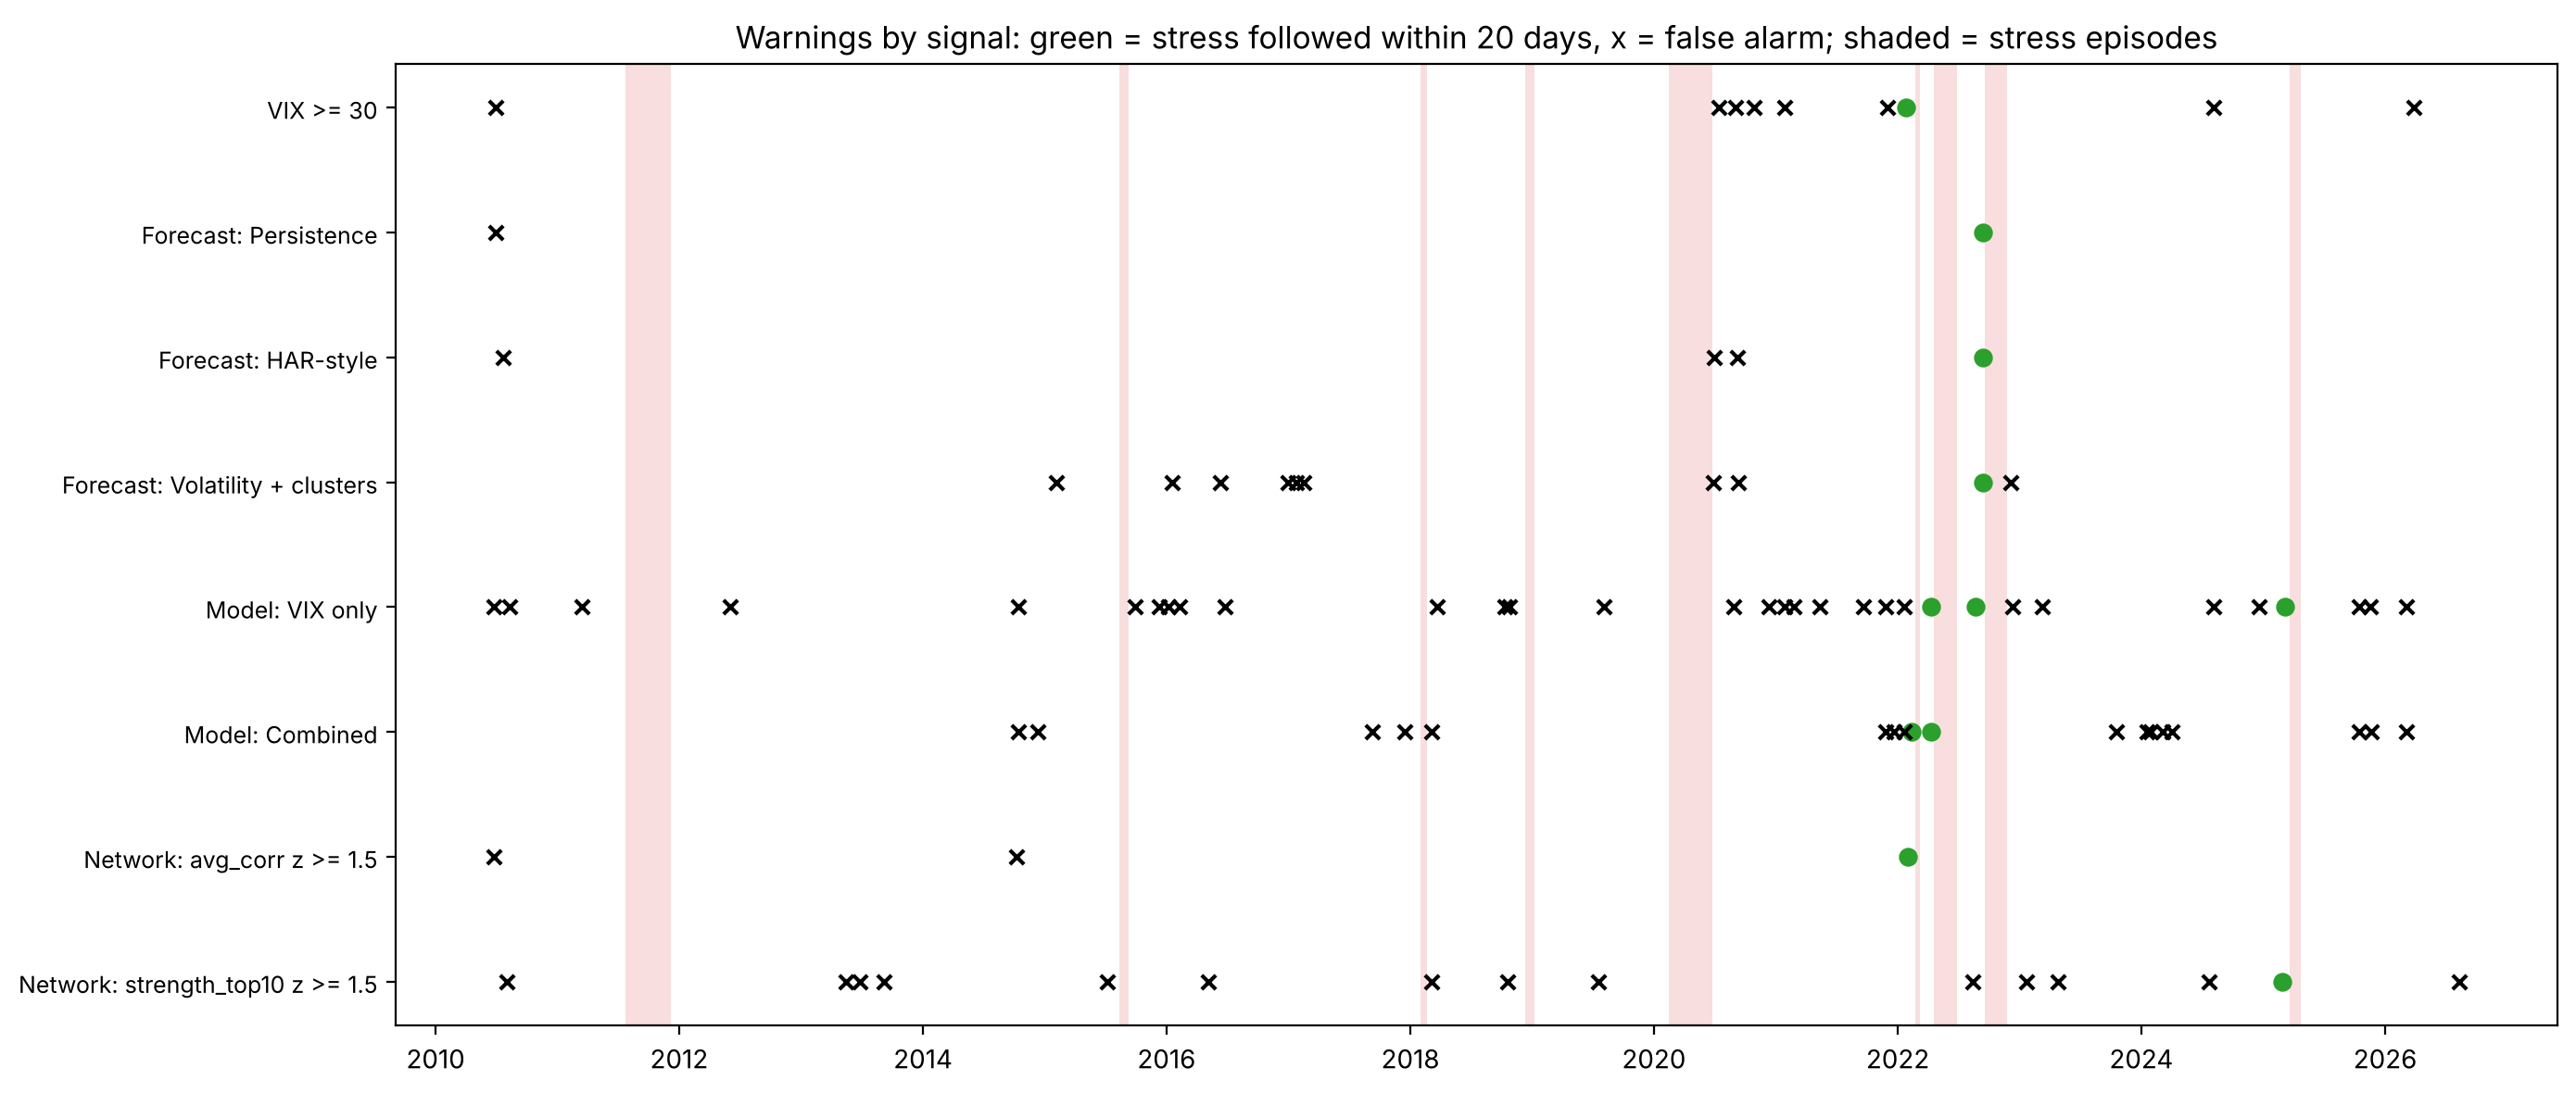

In [8]:
fig, ax = plt.subplots(figsize=(14, 6))
names_list = list(results)
st = stress.loc[START:END]
for s, e in zip(ae.episode_starts(st), st.index[(st == 1) & (st.shift(-1, fill_value=0) == 0)]):
    ax.axvspan(s, e, color="tab:red", alpha=0.15, lw=0)
for i, name in enumerate(names_list):
    ev = results[name].events
    ev = ev[(ev["start"] >= START) & (ev["start"] <= END) & ~ev["during_stress"]]
    ax.scatter(ev.loc[ev["true_warning"], "start"], [i] * ev["true_warning"].sum(), marker="o", color="tab:green", s=40, zorder=3)
    ax.scatter(ev.loc[ev["false_alarm"], "start"], [i] * ev["false_alarm"].sum(), marker="x", color="black", s=30, zorder=3)
ax.set_yticks(range(len(names_list))); ax.set_yticklabels(names_list, fontsize=9)
ax.invert_yaxis()
ax.set_title("Warnings by signal: green = stress followed within 20 days, x = false alarm; shaded = stress episodes")
plt.tight_layout(); plt.show()

## 6. Findings

All numbers come from the outputs above. 9 stress episodes start in the window.

1. **Most warnings are false alarms, for every signal.** False alarm shares range from 50% to 93% (Section 2). No signal warned of more than 3 of the 9 episodes.
2. **VIX >= 30 confirms stress more than it warns.** 12 of its alert events started during an episode, against 9 that started on calm days; of those 9, 8 were false alarms (0.49 a year), and it warned of 1 episode (Feb 2022, 20 days ahead).
3. **The volatility forecasts react, they don't warn.** Predicted volatility >= 25% gives very few false alarms (0.06 a year for persistence, 0.19 for HAR-style) but warned of only 1 episode, Sept 2022, 4 days ahead. Most of their alerts (9 to 11) start once stress has begun.
4. **The early-warning models catch the most, at the highest cost.** The VIX-only model warned of 3 episodes (both spring and autumn 2022 legs and the 2025 tariff selloff, 6 to 18 days ahead) but raised 29 false alarms, 1.79 a year. The combined model caught 2 with 16 false alarms.
5. **Network signals: one catch each.** `avg_corr` z >= 1.5 warned of Feb 2022 (16 days ahead) with only 2 false alarms in 16 years; `strength_top10` warned of the 2025 selloff (16 days) but had 14 false alarms. The Week 4 rise before episodes (median z about 0.6 to 0.9) is real but too small to cross a 1.5 threshold.
6. **Every catch is in 2022-2026** (Section 4a). No signal warned of 2011, 2015, either 2018 episode or COVID. 2020-21 has the most false alarms: VIX stayed above 30 after the crash (2.50 false alarms a year; 3.49 for the VIX-only model).
7. **The early-warning models only beat chance in 2022-2026** (Section 4c): PR-AUC 0.219 for VIX only against a base rate of 0.076. In the three earlier periods both models are at or below the base rate. The Week 5 overall result is driven by one period.
8. **Forecast accuracy by period** (Section 4b): HAR-style beats persistence in every period (skill 0.09 to 0.17). Volatility + clusters beats persistence in three periods but is much worse in 2013-19 (skill -0.23), so the cluster features help in stress-heavy periods and hurt in calm ones.

**Caveats.** 9 episodes is a small sample, and 3 of them are overlapping legs of 2022, which flatters signals that fired in 2022. Thresholds (VIX 30, 25%, z 1.5, top 10%) were fixed in advance, not tuned; other thresholds trade false alarms for catches. Alerts that start during an episode are not counted as warnings.

**For the results review meeting:** the honest main finding is that same-day detection works (Week 5) but no signal reliably warns 20 days ahead across periods; network features add one early catch (Feb 2022) at a low false alarm cost.

## 7. Save

In [9]:
out = ROOT / "notebooks" / "outputs" / "salah_week6"
out.mkdir(parents=True, exist_ok=True)
overall.to_csv(out / "false_alarms_overall.csv")
by_episode.to_csv(out / "warnings_by_episode.csv")
by_period.to_csv(out / "false_alarms_by_period.csv")
forecast_by_period.to_csv(out / "forecast_accuracy_by_period.csv")
model_by_period.to_csv(out / "early_warning_models_by_period.csv")
fig.savefig(out / "warnings_timeline.png", dpi=150, bbox_inches="tight")
print("Saved to", out.relative_to(ROOT))

Saved to notebooks/outputs/salah_week6
